# BigMart Gamma: five-part walkthrough


## Part 1 — Set up and understand the data

In [1]:
from pathlib import Path
import shutil
import os
import sys

os.chdir("/content")
Path("data").mkdir(exist_ok=True)

file_patterns = {
    "train*.csv": "train.csv",
    "test*.csv": "test.csv",
    "sample_submission*.csv": "sample_submission.csv"
}

for pattern, filename in file_patterns.items():
    matching_files = list(Path("/content").glob(pattern))

    assert matching_files, f"Please upload the file matching: {pattern}"

    uploaded_file = matching_files[0]
    destination = Path("data") / filename
    shutil.copy2(uploaded_file, destination)

    print(f"Ready: {filename}")

Ready: train.csv
Ready: test.csv
Ready: sample_submission.csv


### 1.2 Import the tools
pandas handles tables; NumPy performs calculations; sklearn trains and evaluates the model; joblib saves it; matplotlib draws graphs.

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, SplineTransformer
from sklearn.linear_model import GammaRegressor
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
TARGET = 'Item_Outlet_Sales'
KEYS = ['Item_Identifier', 'Outlet_Identifier']

### 1.3 Read the three CSV files
Train contains known sales. Test needs predictions. The sample provides the submission format.

In [3]:
folder = ROOT / 'results'
folder.mkdir(exist_ok=True)
train = pd.read_csv(ROOT / 'data/train.csv')
test = pd.read_csv(ROOT / 'data/test.csv')
template = pd.read_csv(ROOT / 'data/sample_submission.csv')
print('Train:', train.shape, 'Test:', test.shape)
print(train.head().to_string(index=False))

Train: (8523, 12) Test: (5681, 11)
Item_Identifier  Item_Weight Item_Fat_Content  Item_Visibility             Item_Type  Item_MRP Outlet_Identifier  Outlet_Establishment_Year Outlet_Size Outlet_Location_Type       Outlet_Type  Item_Outlet_Sales
          FDA15         9.30          Low Fat         0.016047                 Dairy  249.8092            OUT049                       1999      Medium               Tier 1 Supermarket Type1          3735.1380
          DRC01         5.92          Regular         0.019278           Soft Drinks   48.2692            OUT018                       2009      Medium               Tier 3 Supermarket Type2           443.4228
          FDN15        17.50          Low Fat         0.016760                  Meat  141.6180            OUT049                       1999      Medium               Tier 1 Supermarket Type1          2097.2700
          FDX07        19.20          Regular         0.000000 Fruits and Vegetables  182.0950            OUT010             

### 1.4 Inspect missing values
Weight and outlet size are not used by this model, so their missing values do not need imputation.

In [4]:
print(train.isna().sum())
train.isna().sum().to_csv(folder / 'missing_values.csv')

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64


### 1.5 Check the inputs
An assert stops the program if a required condition fails. MRP and target sales must be positive for this design.

In [5]:
for frame in (train, test):
    assert frame[KEYS + ['Item_MRP']].notna().all().all()
    assert (frame.Item_MRP > 0).all()
    assert not frame[KEYS].duplicated().any()
assert (train[TARGET] > 0).all()
assert template[KEYS].equals(test[KEYS])
print('Input checks passed.')

Input checks passed.


## Part 2 — Build the model inputs

### 2.1 Extract the product number
For FDA15, extract 15. reshape(-1, 1) makes the single-column matrix sklearn expects. This is an empirical ID pattern, not a physical product property.

In [6]:
def product_number(frame):
    suffix = frame['Item_Identifier'].str.extract(r'(\d+)$')[0]
    numbers = suffix.astype(float).to_numpy()
    return numbers.reshape(-1, 1)

print(product_number(train.head()))

[[15.]
 [ 1.]
 [15.]
 [ 7.]
 [19.]]


### 2.2 Describe how inputs are combined
The encoder creates store indicators. Multiplying these by log(MRP) gives store-specific price effects. The spline represents a smooth product-number curve. transform applies already learned rules.

In [7]:
def encode(frame, encoder, spline):
    store_columns = encoder.transform(frame[['Outlet_Identifier']])
    log_price = np.log(frame['Item_MRP'].to_numpy()).reshape(-1, 1)
    store_price_columns = store_columns * log_price
    product_curve = spline.transform(product_number(frame))
    return np.column_stack([
        store_columns,
        store_price_columns,
        product_curve
    ])

### 2.3 Create a reusable training function
fit learns the encoder, spline and Gamma coefficients using only the rows passed in. Keeping these together lets each CV fold learn its own transformations.

In [8]:
def fit_model(frame, sales):
    # Learn which stores occur in these training rows.
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    encoder.fit(frame[['Outlet_Identifier']])

    # Learn the spline basis from these training rows.
    spline = SplineTransformer(n_knots=16, degree=3)
    spline.fit(product_number(frame))

    # Convert inputs, then fit the sales model.
    inputs = encode(frame, encoder, spline)
    estimator = GammaRegressor(alpha=0.0001, max_iter=5000)
    estimator.fit(inputs, sales)
    return {'encoder': encoder, 'spline': spline, 'estimator': estimator}

### 2.4 Create a reusable prediction function
Prediction uses the saved transformations and model; it does not learn again.

In [9]:
def predict(bundle, frame):
    inputs = encode(frame, bundle['encoder'], bundle['spline'])
    return bundle['estimator'].predict(inputs)

## Part 3 — Train and cross-validate

### 3.1 Define the three scores
Lower RMSE and MAE are better. Higher R-squared is better; it is not classification accuracy.

In [10]:
def scores(actual, estimated):
    rmse = np.sqrt(mean_squared_error(actual, estimated))
    mae = mean_absolute_error(actual, estimated)
    r_squared = r2_score(actual, estimated)
    return {'RMSE': float(rmse), 'MAE': float(mae), 'R2': float(r_squared)}

### 3.2 Reserve evaluation rows
80% becomes development data; 20% becomes evaluation data. Seed 42 reproduces the earlier split. That evaluation split has already been inspected.

In [11]:
development, evaluation = train_test_split(
    train, test_size=0.2, random_state=42
)
print('Development rows:', len(development))
print('Evaluation rows:', len(evaluation))

Development rows: 6818
Evaluation rows: 1705


### 3.3 Set up five folds
Each development row will be validated once and used for learning in four other folds.

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
fold_rows = []

### 3.4 Run cross-validation
In every loop: select learning rows, fit transformations and model, predict validation rows, and record errors.

In [13]:
for number, (a, b) in enumerate(cv.split(development), start=1):
    learning = development.iloc[a]
    validation = development.iloc[b]
    fitted = fit_model(learning, learning[TARGET])
    validation_predictions = predict(fitted, validation)
    fold_scores = scores(validation[TARGET], validation_predictions)
    fold_rows.append({'fold': number, **fold_scores})
    print('Fold', number, fold_scores)

Fold 1 {'RMSE': 1113.5384546310584, 'MAE': 787.5714618282542, 'R2': 0.5864943653763749}
Fold 2 {'RMSE': 1023.1668187615497, 'MAE': 727.1178767107357, 'R2': 0.6139567357775628}
Fold 3 {'RMSE': 1079.4972162800732, 'MAE': 748.0213045772715, 'R2': 0.5854213621384426}
Fold 4 {'RMSE': 1072.0082728885711, 'MAE': 758.118480478506, 'R2': 0.6178999410904622}
Fold 5 {'RMSE': 1084.2572429995805, 'MAE': 749.4506583697573, 'R2': 0.6373934530232623}


### 3.5 Summarize the fold results
The mean summarizes performance; the standard deviation describes variation across these folds.

In [14]:
folds = pd.DataFrame(fold_rows)
folds.to_csv(folder / 'cross_validation.csv', index=False)
print(folds)
print('Mean CV RMSE:', folds.RMSE.mean())
print('Fold standard deviation:', folds.RMSE.std(ddof=0))

   fold         RMSE         MAE        R2
0     1  1113.538455  787.571462  0.586494
1     2  1023.166819  727.117877  0.613957
2     3  1079.497216  748.021305  0.585421
3     4  1072.008273  758.118480  0.617900
4     5  1084.257243  749.450658  0.637393
Mean CV RMSE: 1074.4936011121667
Fold standard deviation: 29.27620500274063


## Part 4 — Evaluate and understand errors

### 4.1 Fit development data and predict evaluation rows
This model learns from all 6,818 development rows. Evaluation labels are used only to calculate the scores.

In [15]:
model = fit_model(development, development[TARGET])
estimates = predict(model, evaluation)
print(scores(evaluation[TARGET], estimates))

{'RMSE': 1005.7579306242619, 'MAE': 704.0546354743047, 'R2': 0.6278292290861192}


### 4.2 Compare with a simple average guess
The baseline predicts the development mean for every evaluation row.

In [16]:
baseline_predictions = np.repeat(
    development[TARGET].mean(), len(evaluation)
)
print('Mean baseline:', scores(evaluation[TARGET], baseline_predictions))

Mean baseline: {'RMSE': 1651.989750472933, 'MAE': 1321.738728500184, 'R2': -0.004083955591431154}


### 4.3 Save the metrics
This records the scores and the limitation of the previously examined evaluation split.

In [17]:
summary = {'development_rows': len(development), 'evaluation_rows': len(evaluation),
           'cv_rmse_mean': float(folds.RMSE.mean()),
           'cv_rmse_sd': float(folds.RMSE.std(ddof=0)),
           'evaluation': scores(evaluation[TARGET], estimates),
           'mean_baseline': scores(evaluation[TARGET], np.repeat(development[TARGET].mean(),len(evaluation))),
           'evaluation_note': 'Previously examined split: comparative diagnostic, not a new untouched test.'}

(folder / 'metrics.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "development_rows": 6818,
  "evaluation_rows": 1705,
  "cv_rmse_mean": 1074.4936011121667,
  "cv_rmse_sd": 29.27620500274063,
  "evaluation": {
    "RMSE": 1005.7579306242619,
    "MAE": 704.0546354743047,
    "R2": 0.6278292290861192
  },
  "mean_baseline": {
    "RMSE": 1651.989750472933,
    "MAE": 1321.738728500184,
    "R2": -0.004083955591431154
  },
  "evaluation_note": "Previously examined split: comparative diagnostic, not a new untouched test."
}


### 4.4 Inspect individual mistakes
Residual = actual minus predicted. Positive residuals mean the model predicted too little.

In [18]:
details = evaluation[KEYS+[TARGET]].copy()
details['Predicted_Sales'] = estimates
details['Residual'] = details[TARGET] - estimates
details.to_csv(folder / 'evaluation_predictions.csv', index=False)

print(details.head().to_string(index=False))

Item_Identifier Outlet_Identifier  Item_Outlet_Sales  Predicted_Sales    Residual
          FDI28            OUT013          1743.0644      1127.754110  615.310290
          NCM17            OUT046           356.8688       800.134034 -443.265234
          FDC14            OUT049           377.5086       675.637787 -298.129187
          DRC36            OUT027          5778.4782      5028.920246  749.557954
          FDS27            OUT035          2356.9320      3120.398243 -763.466243


### 4.5 Plot actual against predicted
Points on the dashed diagonal are perfect predictions.

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(evaluation[TARGET], estimates, s=9, alpha=.25, color='teal')
limit = max(evaluation[TARGET].max(), estimates.max())
ax[0].plot([0, limit], [0, limit], '--', color='orange')
ax[0].set(xlabel='Actual sales', ylabel='Predicted sales', title='Evaluation predictions')

[Text(0.5, 0, 'Actual sales'),
 Text(0, 0.5, 'Predicted sales'),
 Text(0.5, 1.0, 'Evaluation predictions')]

### 4.6 Plot residuals and display the figure
This completes the figure started in the previous cell. Look for large errors and systematic underprediction.

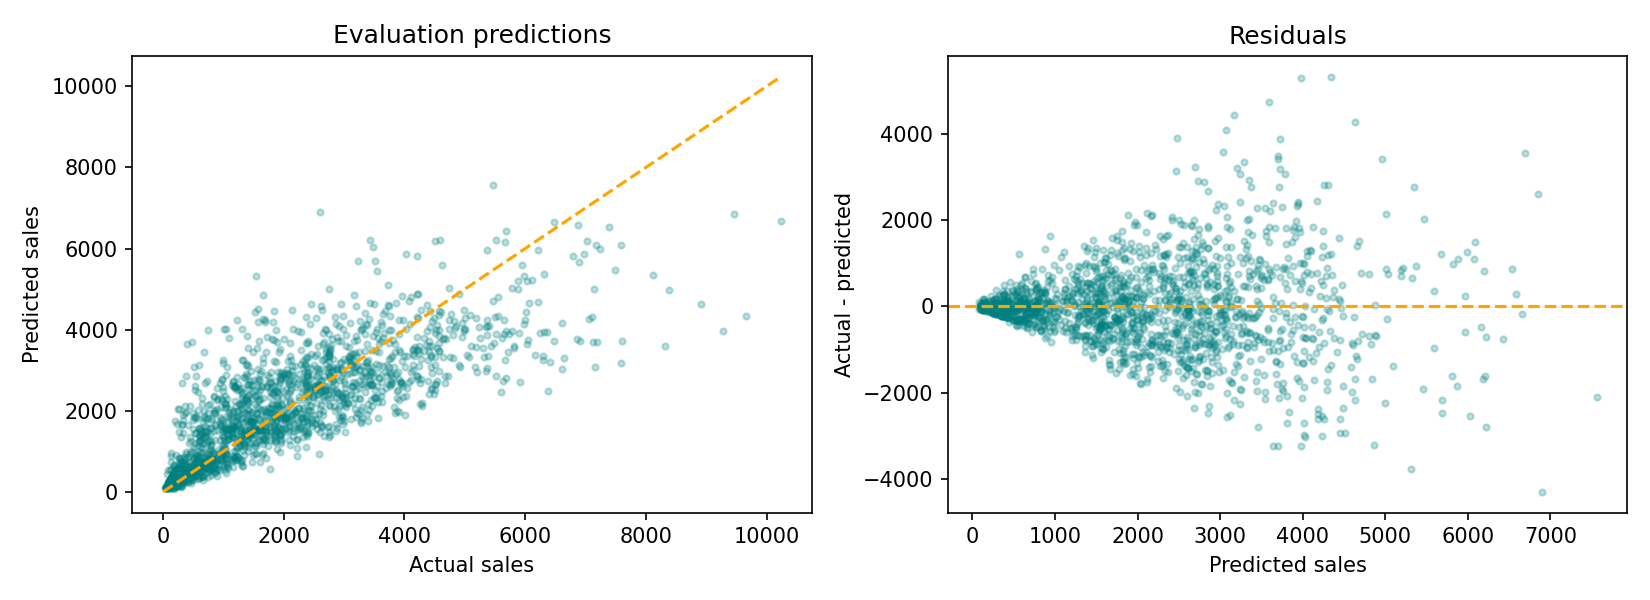

In [20]:
ax[1].scatter(estimates, details.Residual, s=9, alpha=.25, color='teal')
ax[1].axhline(0, color='orange', linestyle='--')
ax[1].set(xlabel='Predicted sales', ylabel='Actual - predicted', title='Residuals')
fig.tight_layout()
fig.savefig(folder / 'diagnostics.png', dpi=150)
plt.close(fig)
from IPython.display import display, Image
display(Image(filename=str(folder / 'diagnostics.png')))

## Part 5 — Create and check the competition submission

### 5.1 Train the final model
Use all 8,523 labeled rows for the final model. Its competition test score is still unknown.

In [21]:
final = fit_model(train, train[TARGET])

### 5.2 Predict test sales
Keep the sample file IDs and replace its placeholder sales with model predictions.

In [22]:
submission = template.copy()
submission[TARGET] = predict(final, test)
print(submission.head())

  Item_Identifier Outlet_Identifier  Item_Outlet_Sales
0           FDW58            OUT049        1822.954702
1           FDW14            OUT017        1488.477446
2           NCN55            OUT010         619.071241
3           FDQ58            OUT017        2663.888726
4           FDY38            OUT027        6511.421382


### 5.3 Validate and save the CSV
Check column order, row count, matching IDs, finite numbers and positive sales. index=False prevents an extra CSV column.

In [23]:
assert len(submission) == len(test)
assert submission.columns.tolist() == KEYS + [TARGET]
assert submission[KEYS].equals(test[KEYS])
assert np.isfinite(submission[TARGET]).all()
assert (submission[TARGET] > 0).all()
submission.to_csv(folder / 'gamma_submission.csv', index=False)
print('Submission saved:', submission.shape)

Submission saved: (5681, 3)


### 5.4 Save and reload the model
The bundle includes preprocessing and the fitted estimator. Check that reloading produces identical predictions.

In [24]:
joblib.dump(final, folder / 'gamma_model.joblib')
restored = joblib.load(folder / 'gamma_model.joblib')
np.testing.assert_allclose(predict(restored, test), submission[TARGET])
print('Saved model check passed.')

Saved model check passed.


### 5.5 Demonstrate one prediction
Show the selected test record and its predicted sales.

In [25]:
row = test.iloc[[0]]
print(row[KEYS + ['Item_MRP']].to_string(index=False))
print('Estimated sales:', round(float(predict(restored, row)[0]), 2))

Item_Identifier Outlet_Identifier  Item_MRP
          FDW58            OUT049  107.8622
Estimated sales: 1822.95


### 5.6 Download the competition CSV
In Colab this downloads the prediction file. Locally, it is already in the results folder.

In [27]:
from google.colab import files

files.download(str(folder / "gamma_submission.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>